# Homework 1 – Option basics, BSM model


In [18]:
import matplotlib.pyplot as plt
import numpy as np
from typing import Dict, List, Optional
from typing import Dict, List, Optional, Union
import numpy as np
from scipy.stats import norm

## BSM call pricer (lecture cells 10, 39, 43)

In [19]:
#1.B

"""The pricing function of European call option"""
def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> Dict[str, np.ndarray]:
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    """
    # check conditions
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5

    N_d1_vec = norm.cdf(d1_vec)
    N_d2_vec = norm.cdf(d2_vec)

    #-----------------------#
    # CHANGES ARE FROM HERE!#
    #-----------------------#

    price_vec =  N_d1_vec * S0 - K * np.exp((-1.0)*r*T) * N_d2_vec

    # Greeks by defintion

    delta_vec = N_d1_vec
    gamma_vec = norm.pdf(d1_vec) / (S0 * sigma * T**0.5)
    vega_vec  = S0 * norm.pdf(d1_vec) * T**0.5
    theta_vec = (-S0 * norm.pdf(d1_vec) * sigma / (2 * T**0.5)
                 - r * K * np.exp(-r * T) * N_d2_vec)
    rho_vec   = K * T * np.exp(-r * T) * N_d2_vec


    return {
        "price": price_vec,
        "delta": delta_vec,
        "gamma": gamma_vec,
        "vega":  vega_vec,
        "theta": theta_vec,
        "rho":   rho_vec,
    }

In [20]:
# checking whether it works

black_scholes_eur_call(r=0.05, T=1.0, S0=20.0, sigma=0.3, K=(20.0, 10.0, 15.0))

{'price': array([ 2.84625096, 10.49652216,  6.05962203]),
 'delta': array([0.62425173, 0.99569492, 0.89895274]),
 'gamma': array([0.06323882, 0.00210872, 0.02947289]),
 'vega': array([7.58865866, 0.25304602, 3.53674654]),
 'theta': array([-1.62023798, -0.50882572, -1.12648362]),
 'rho': array([ 9.6387836 ,  9.41737631, 11.91943286])}

In [21]:
#1.C
"""The pricing function of European put option"""
def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float,
                          K: Union[float, List[float], np.ndarray]) -> Dict[str, np.ndarray]:
    """
    Black-Scholes pricer of European put option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)

    returns: dict of arrays (one entry per strike) with keys
             price, delta, gamma,
             vega  (per 1.00 change in sigma),
             theta (per year),
             rho   (per 1.00 change in r)
    """
    # check conditions
    assert sigma > 0

    # turn K into an array, so that the function works for one strike or many
    K = np.atleast_1d(np.asarray(K, dtype=float))

    # d1 and d2 are the same as for the call
    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5

    # the put formula uses N(-d1) and N(-d2) instead of N(d1) and N(d2)
    N_minus_d1_vec = norm.cdf(-d1_vec)
    N_minus_d2_vec = norm.cdf(-d2_vec)

    # standard normal density at d1 (appears in gamma, vega and theta)
    n_d1_vec = norm.pdf(d1_vec)

    # discount factor: value today of 1 unit paid at time T
    discount_factor = np.exp(-r * T)


    # price: present value of the strike received minus the value of the share given up
    price_vec = K * discount_factor * N_minus_d2_vec - S0 * N_minus_d1_vec

    # Greeks by definition

    # delta: negative, a put loses value when the share price rises
    delta_vec = -N_minus_d1_vec

    # gamma: identical to the call's gamma
    gamma_vec = n_d1_vec / (S0 * sigma * T**0.5)

    # vega: identical to the call's vega
    vega_vec  = S0 * n_d1_vec * T**0.5

    # theta: same first term as the call, but the second term has a plus sign
    theta_vec = (-S0 * n_d1_vec * sigma / (2 * T**0.5)
                 + r * K * discount_factor * N_minus_d2_vec)

    # rho: negative, a higher rate lowers the present value of the strike received
    rho_vec   = -K * T * discount_factor * N_minus_d2_vec


    return {
        "price": price_vec,
        "delta": delta_vec,
        "gamma": gamma_vec,
        "vega":  vega_vec,
        "theta": theta_vec,
        "rho":   rho_vec,
    }

#code cleanup and comments were done by Claude Opus 5.5 Medium

In [22]:
# 1d
# Put-call parity check: c - p should equal S0 - K * exp(-rT)
r, T, S0, sigma = 0.05, 1.0, 20.0, 0.3
K = np.array([20.0, 10.0, 15.0])

call = black_scholes_eur_call(r=r, T=T, S0=S0, sigma=sigma, K=K)
put  = black_scholes_eur_put(r=r, T=T, S0=S0, sigma=sigma, K=K)

left_side  = call["price"] - put["price"]     # c - p
right_side = S0 - K * np.exp(-r * T)          # S0 - K e^{-rT}

print("c - p          :", left_side)
print("S0 - K e^(-rT) :", right_side)
print("parity holds   :", np.allclose(left_side, right_side))

c - p          : [ 0.97541151 10.48770575  5.73155863]
S0 - K e^(-rT) : [ 0.97541151 10.48770575  5.73155863]
parity holds   : True


available expiries: ('2026-10-23', '2026-10-26', '2026-10-28', '2026-10-30', '2026-11-06', '2026-11-13', '2026-11-20', '2026-11-27')
S0 = 386.77,  r = 0.0406,  expiry = 2026-10-30,  T = 0.0247 years
 strike  c - p (mid)  S0 - K e^(-rT)  deviation  sell band  buy band  holds in spread
  310.0       77.790          77.080      0.710      76.74     78.84             True
  315.0       72.305          72.085      0.220      71.79     72.82             True
  320.0       67.310          67.090      0.220      66.82     67.80             True
  325.0       62.200          62.095      0.105      61.36     63.04             True
  330.0       57.390          57.100      0.290      56.45     58.33             True
  335.0       52.545          52.105      0.440      51.68     53.41             True
  340.0       47.080          47.110     -0.030      46.82     47.34             True
  342.5       45.015          44.613      0.402      44.41     45.62             True
  345.0       42.645       

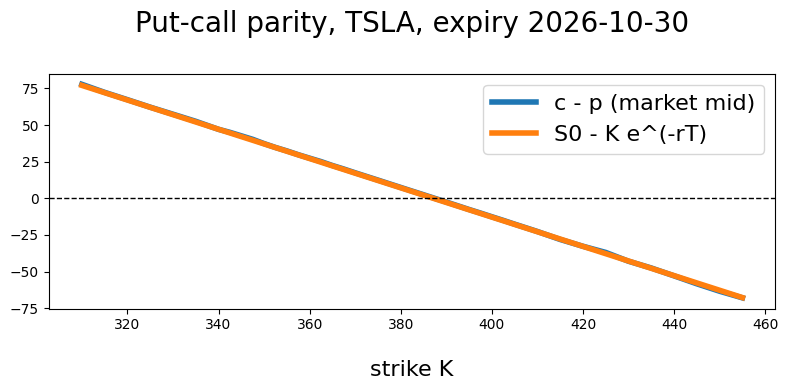

In [23]:
import yfinance as yf
import pandas as pd
import numpy as np

# brainstorming how to check, commenting the final version of the code and reading in data was done by CLaude Opus 5.5 Medium. Also the plot was the AI's idea as well

# ---------------------------------------------------------------
# 1. Market inputs: spot price, risk-free rate, maturity
# ---------------------------------------------------------------

ticker_symbol = "TSLA"            # non-dividend-paying stock
ticker = yf.Ticker(ticker_symbol)

# current spot price of the share
S0 = ticker.history(period="1d")["Close"].iloc[-1]

# risk-free rate: yield of the 13-week US T-bill (^IRX), quoted in percent
r = yf.Ticker("^IRX").history(period="5d")["Close"].iloc[-1] / 100

# list of available expiry dates, as strings 'YYYY-MM-DD'
print("available expiries:", ticker.options[:8])

# pick one expiry, a few weeks out
expiry = ticker.options[3]

# time to maturity in years
T = (pd.Timestamp(expiry) - pd.Timestamp.today().normalize()).days / 365

print(f"S0 = {S0:.2f},  r = {r:.4f},  expiry = {expiry},  T = {T:.4f} years")


# ---------------------------------------------------------------
# 2. Option chain: calls and puts with the same strikes
# ---------------------------------------------------------------

chain = ticker.option_chain(expiry)

calls = chain.calls[["strike", "bid", "ask"]]
puts  = chain.puts[["strike", "bid", "ask"]]

# keep only strikes that exist for both calls and puts
data = calls.merge(puts, on="strike", suffixes=("_call", "_put"))

# drop strikes without a real quote (bid = 0 means nobody is buying)
data = data[(data["bid_call"] > 0) & (data["bid_put"] > 0)]

# keep strikes within +-20% of the spot, where trading is liquid
data = data[(data["strike"] > 0.8 * S0) & (data["strike"] < 1.2 * S0)]

K = data["strike"].to_numpy()


# ---------------------------------------------------------------
# 3. The two sides of put-call parity
# ---------------------------------------------------------------

# mid price: halfway between bid and ask, our best single estimate of the price
call_mid = (data["bid_call"] + data["ask_call"]) / 2
put_mid  = (data["bid_put"]  + data["ask_put"])  / 2

# left side: market value of (long call, short put)
c_minus_p = (call_mid - put_mid).to_numpy()

# right side: value of a long forward, S0 - K e^{-rT}
parity_value = S0 - K * np.exp(-r * T)

deviation = c_minus_p - parity_value


# ---------------------------------------------------------------
# 4. Does parity hold within the bid-ask spread?
# ---------------------------------------------------------------

# cheapest way to BUY (long call, short put): pay the call ask, receive the put bid
cost_to_buy  = (data["ask_call"] - data["bid_put"]).to_numpy()

# best way to SELL (short call, long put): receive the call bid, pay the put ask
proceeds_to_sell = (data["bid_call"] - data["ask_put"]).to_numpy()

# no arbitrage in practice: the parity value lies between these two numbers
holds_within_spread = (proceeds_to_sell <= parity_value) & (parity_value <= cost_to_buy)


results = pd.DataFrame({
    "strike":           K,
    "c - p (mid)":      c_minus_p,
    "S0 - K e^(-rT)":   parity_value,
    "deviation":        deviation,
    "sell band":        proceeds_to_sell,
    "buy band":         cost_to_buy,
    "holds in spread":  holds_within_spread,
})

print(results.round(3).to_string(index=False))
print(f"\nparity holds within the bid-ask spread for "
      f"{holds_within_spread.sum()} of {len(K)} strikes")



In [24]:
# I used Claude Opus 5.5 Medium heavily for this task, most of the final code was done by it

# All layout settings in one place. Anything not given in `layout` falls back to these values.
DEFAULT_LAYOUT = {
    # figure
    "figsize":         (8, 4),

    # lines
    "linestyle":       "solid",
    "linewidth":       4,
    "linestyles":      None,     # one linestyle per line, e.g. ["solid", "dashed"]; overrides "linestyle"
    "colors":          None,     # one color per line, e.g. ["blue", "red"]; None = matplotlib's default colors
    "marker":          None,     # e.g. "o" to mark the data points

    # text
    "title":           None,
    "title_fontsize":  20,
    "title_pad":       30,
    "x_label":         None,
    "y_label":         None,
    "label_fontsize":  16,
    "label_pad":       20,
    "legend_fontsize": 16,
    "legend_loc":      "best",

    # axes
    "x_lim":           None,     # e.g. (10, 30)
    "y_lim":           None,
    "log_y":           False,    # logarithmic y-axis
    "grid":            False,
    "zero_line":       True,     # dashed horizontal line at y = 0
    "v_lines":         None,     # x-positions of dotted vertical lines, e.g. [S0] or [K]

    # output
    "save_path":       None,     # e.g. "call_price.png" to save the figure to a file
}


def my_plotter(x: List[float],
               y,
               layout: Optional[Dict] = None,
               names: Optional[List[str]] = None) -> None:
    """
    Plot one or several lines against the same x values.

    param x: x values
    param y: one list of y values, or a list of such lists (one per line)
    param layout: settings that override DEFAULT_LAYOUT, e.g. {"title": "...", "grid": True}
    param names: legend label for each line (optional)
    """
    # 1. Combine defaults and user settings: the user's values win
    layout = layout or {}

    unknown_keys = set(layout) - set(DEFAULT_LAYOUT)
    if unknown_keys:
        raise ValueError(f"Unknown layout keys: {unknown_keys}")

    settings = {**DEFAULT_LAYOUT, **layout}

    # 2. If y is a single line (its first element is a number), wrap it into a list of lines
    if np.ndim(y[0]) == 0:
        y = [y]

    if names is not None and len(names) != len(y):
        raise ValueError("Length of names is not matching with number of plotted y lists.")

    # 3. Draw the lines
    plt.figure(figsize=settings["figsize"])

    for i, y_item in enumerate(y):
        plot_kwargs = {
            "linestyle": settings["linestyle"],
            "linewidth": settings["linewidth"],
            "marker":    settings["marker"],
        }
        if settings["linestyles"] is not None:
            plot_kwargs["linestyle"] = settings["linestyles"][i]
        if settings["colors"] is not None:
            plot_kwargs["color"] = settings["colors"][i]
        if names is not None:
            plot_kwargs["label"] = names[i]

        plt.plot(x, y_item, **plot_kwargs)

    # 4. Text: title and axis labels
    if settings["title"] is not None:
        plt.title(settings["title"], fontsize=settings["title_fontsize"], pad=settings["title_pad"])
    if settings["x_label"] is not None:
        plt.xlabel(settings["x_label"], fontsize=settings["label_fontsize"], labelpad=settings["label_pad"])
    if settings["y_label"] is not None:
        plt.ylabel(settings["y_label"], fontsize=settings["label_fontsize"], labelpad=settings["label_pad"])

    # 5. Axes features
    ax = plt.gca()  # gca: get current axes

    if settings["zero_line"]:
        ax.axhline(0, linestyle="--", color="black", linewidth=1)
    if settings["v_lines"] is not None:
        for x_position in settings["v_lines"]:
            ax.axvline(x_position, linestyle=":", color="gray", linewidth=1.5)
    if settings["grid"]:
        ax.grid(True, alpha=0.3)
    if settings["log_y"]:
        ax.set_yscale("log")
    if settings["x_lim"] is not None:
        ax.set_xlim(settings["x_lim"])
    if settings["y_lim"] is not None:
        ax.set_ylim(settings["y_lim"])

    if names is not None:
        plt.legend(fontsize=settings["legend_fontsize"], loc=settings["legend_loc"])

    # 6. Output
    plt.tight_layout()
    if settings["save_path"] is not None:
        plt.savefig(settings["save_path"], dpi=150, bbox_inches="tight")
    plt.show()

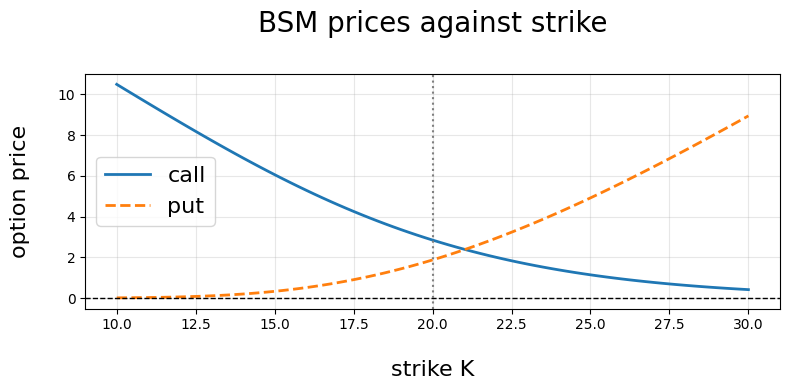

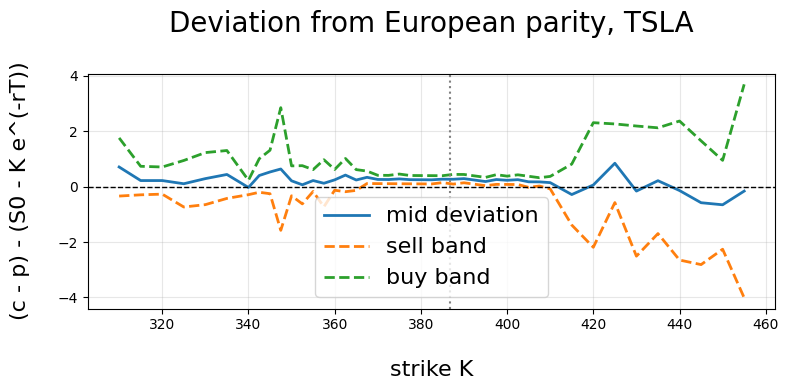

In [26]:
# in use

strikes = np.linspace(10, 30, 81)
call = black_scholes_eur_call(r=0.05, T=1.0, S0=20.0, sigma=0.3, K=strikes)
put  = black_scholes_eur_put(r=0.05, T=1.0, S0=20.0, sigma=0.3, K=strikes)

my_plotter(
    x=strikes.tolist(),
    y=[call["price"].tolist(), put["price"].tolist()],
    layout={
        "title":      "BSM prices against strike",
        "x_label":    "strike K",
        "y_label":    "option price",
        "colors":     ["tab:blue", "tab:orange"],
        "linestyles": ["solid", "dashed"],
        "linewidth":  2,
        "grid":       True,
        "v_lines":    [20.0],          # mark S0 = at the money
    },
    names=["call", "put"],
)


my_plotter(
    x=K.tolist(),
    y=[deviation.tolist(),
       (proceeds_to_sell - parity_value).tolist(),
       (cost_to_buy - parity_value).tolist()],
    layout={"title": f"Deviation from European parity, {ticker_symbol}",
            "x_label": "strike K",
            "y_label": "(c - p) - (S0 - K e^(-rT))",
            "linewidth": 2,
            "linestyles": ["solid", "dashed", "dashed"],
            "v_lines": [S0],
            "grid": True},
    names=["mid deviation", "sell band", "buy band"],
)